In [2]:
!pip install kaggle
!pip install kagglehub
!pip install pandas
!pip install numpy
!pip install StandardScaler
!pip install scikit-learn

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: C:\Users\Boss\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: C:\Users\Boss\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable


...


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: C:\Users\Boss\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: C:\Users\Boss\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: C:\Users\Boss\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [7]:
!pip install matplotlib

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   -------------------- ------------------- 4.7/9.3 MB 28.1 MB/s eta 0:00:01
   ---------------------------------------  9.2/9.3 MB 25.3 MB/s eta 0:00:01
   ---------------------------------------- 9.3/9.3 MB 23.3 MB/s  0:00:00
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---------------------------------------- 2.5/2.5 MB 44.0 MB/s  0:00:00
   ---------------------------------------- 0.0/7.2 MB ? eta -:--:--
   ---------------------------------------- 7.2/7.2 MB 35.1 MB/s  0:00:00

   ---------------------------------------- 0/7 [pyparsing]
   ----- ---------------------------------- 1/7 [pillow]
   ----- ---------------------------------- 1/7 [pillow]
   ----- ---------------------------------- 1/7 [pillow]
   ----- ---------------------------------- 1/7 [pillow]
   ----- ---------------------------------- 1/7 [p


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: C:\Users\Boss\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [ ]:
import kaggle

kaggle.api.authenticate()
kaggle.api.dataset_download_files(
    "kylefengkfeng209/college-majors-2026-earnings-debt-jobs-ai",
    path="./data",
    unzip=True
)

Dataset URL: https://www.kaggle.com/datasets/kylefengkfeng209/college-majors-2026-earnings-debt-jobs-ai


In [2]:
import pandas as pd
df = pd.read_csv("E:/Code/data sci/data/college_majors_2026.csv")

print(df.shape)
print(df.dtypes)
print(df[["credential_level", "cip_family_title",
          "ai_software_occupation_share",
          "median_earnings_4yr_usd", "median_debt_usd", "pct_working_5yr"]].head(10))
print(df.isna().mean().sort_values(ascending=False).head(15))

(227980, 72)
program_id                 str
unitid                 float64
opeid6                   int64
institution_name           str
institution_control        str
                        ...   
ai_tool_examples           str
earnings_4yr_status        str
earnings_1yr_status        str
earnings_5yr_status        str
debt_status                str
Length: 72, dtype: object
   credential_level                                   cip_family_title  \
0                 1            Health Professions and Related Programs   
1                 1            Health Professions and Related Programs   
2                 1  Business, Management, Marketing, and Related S...   
3                 1     Culinary, Entertainment, and Personal Services   
4                 5                                          Education   
5                 6                                          Education   
6                 8                                          Education   
7                 5         

In [5]:
# เช็กว่ามี column อื่นที่ช่วยยืนยันไหม เช่น ชื่อเต็มของ credential
print(df.filter(regex="credential|level_name|degree_name", axis=1).columns.tolist())

# เทียบ cross-check: สาขาที่ระดับ 3 ควรมีทั้ง Business, Engineering, Health ฯลฯ (สาขาปริญญาตรีทั่วไป)
print(df[df["credential_level"] == 3]["cip_family_title"].value_counts().head(10))

['credential_level', 'credential_name']
cip_family_title
Business, Management, Marketing, and Related Support Services    8625
Health Professions and Related Programs                          5634
Visual and Performing Arts                                       5441
Social Sciences                                                  5218
Education                                                        3764
Biological and Biomedical Sciences                               3680
Engineering                                                      3365
Multi/Interdisciplinary Studies                                  3161
Computer and Information Sciences and Support Services           3119
Physical Sciences                                                2827
Name: count, dtype: int64


In [ ]:
d = df[df["credential_level"] == 3].copy()   # ใช้ตัวเลข ไม่ใช่ string  
print(len(d))   # ควรได้ 71664

driver = "ai_software_occupation_share"
n_before = len(d)
d = d.dropna(subset=[driver])
print(n_before, "->", len(d))

print(d[driver].describe())
print((d[driver] < 0).sum())
print(d.duplicated().sum())

71664
71664 -> 68385
count    68385.000000
mean         0.094086
std          0.168801
min          0.000000
25%          0.000000
50%          0.000000
75%          0.111000
max          1.000000
Name: ai_software_occupation_share, dtype: float64
0
0


ข้อมูลนี้เบ้ขวาอย่างรุนแรง (heavily right-skewed): median และ Q1 เป็น 0 ทั้งคู่ หมายความว่ามากกว่าครึ่งของสาขาวิชามี AI Exposure = 0 พอดี ไม่ใช่แค่น้อย แต่เป็นศูนย์เป๊ะ ส่วนที่เหลือกระจายไปจนถึง 1.0

42281 จาก 68385 = 0.618278862323609


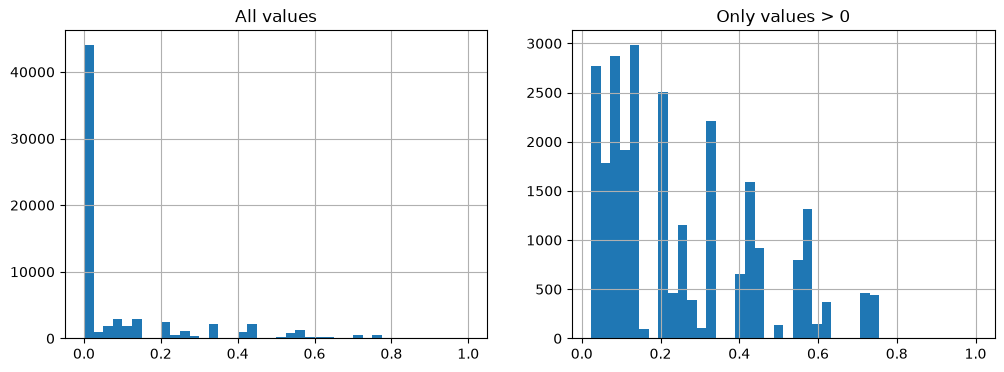

In [8]:
import matplotlib.pyplot as plt

print((d[driver] == 0).sum(), "จาก", len(d), "=", (d[driver] == 0).mean())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
d[driver].hist(bins=40, ax=axes[0])
axes[0].set_title("All values")
d[d[driver] > 0][driver].hist(bins=40, ax=axes[1])
axes[1].set_title("Only values > 0")
plt.show()

In [9]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

X = d[[driver]].copy()
Xs = StandardScaler().fit_transform(X)

results = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Xs)
    sil = silhouette_score(Xs, km.labels_)
    results.append((k, km.inertia_, sil))

result_df = pd.DataFrame(results, columns=["k", "inertia", "silhouette"])
print(result_df)

   k       inertia  silhouette
0  2  13824.909789    0.820802
1  3   6199.570049    0.791030
2  4   2800.126585    0.827699
3  5   1720.688464    0.843659
4  6   1054.131206    0.849661
5  7    601.874170    0.868404
6  8    397.863269    0.885132


In [ ]:
import pandas as pd
import numpy as np

df = pd.read_csv("E:/Code/data sci/data/college_majors_2026.csv")
df.head()
print("\nCount of NaN in each column:\n", df.isnull().sum())

In [10]:
print(df.filter(regex="ai_", axis=1).columns.tolist())

['occupations_using_ai_software', 'ai_software_occupation_share', 'ai_tools_max_per_occupation', 'ai_tool_examples']


In [11]:
print(d["ai_tools_max_per_occupation"].describe())
print(d["ai_tools_max_per_occupation"].isna().mean())
print(d[["ai_software_occupation_share", "ai_tools_max_per_occupation"]].corr())

count    68385.000000
mean         1.552928
std          2.953609
min          0.000000
25%          0.000000
50%          0.000000
75%          1.000000
max         10.000000
Name: ai_tools_max_per_occupation, dtype: float64
0.0
                              ai_software_occupation_share  \
ai_software_occupation_share                      1.000000   
ai_tools_max_per_occupation                       0.787237   

                              ai_tools_max_per_occupation  
ai_software_occupation_share                     0.787237  
ai_tools_max_per_occupation                      1.000000  


In [12]:
drivers = ["ai_software_occupation_share", "ai_tools_max_per_occupation"]
X = d[drivers].dropna()
n_before = len(d)
print(n_before, "->", len(X))

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

Xs = StandardScaler().fit_transform(X)

results = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Xs)
    sil = silhouette_score(Xs, km.labels_)
    results.append((k, km.inertia_, sil))

result_df = pd.DataFrame(results, columns=["k", "inertia", "silhouette"])
print(result_df)

68385 -> 68385
   k       inertia  silhouette
0  2  37308.323505    0.806404
1  3  21131.833955    0.753224
2  4  14917.970783    0.761659
3  5  10174.824380    0.767691
4  6   7092.025608    0.790380
5  7   5069.967899    0.819856
6  8   3487.328737    0.829319


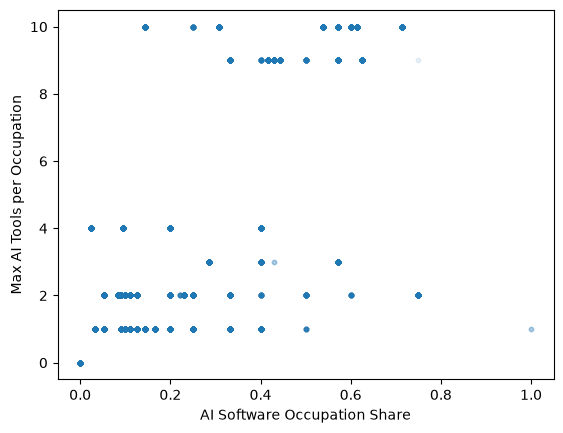

In [13]:
import matplotlib.pyplot as plt
plt.scatter(X["ai_software_occupation_share"], X["ai_tools_max_per_occupation"], alpha=0.1, s=10)
plt.xlabel("AI Software Occupation Share")
plt.ylabel("Max AI Tools per Occupation")
plt.show()

In [14]:
for k in [4, 5, 6]:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Xs)
    d.loc[X.index, f"cluster_k{k}"] = km.labels_
    print(f"--- k={k} ---")
    print(d.groupby(f"cluster_k{k}")[drivers].agg(["count", "mean", "min", "max"]).round(3))
    print()

--- k=4 ---
           ai_software_occupation_share                       \
                                  count   mean    min    max   
cluster_k4                                                     
0.0                               43955  0.002  0.000  0.053   
1.0                                7260  0.442  0.143  0.750   
2.0                                3538  0.407  0.286  1.000   
3.0                               13632  0.126  0.024  0.250   

           ai_tools_max_per_occupation                    
                                 count   mean  min   max  
cluster_k4                                                
0.0                              43955  0.038  0.0   1.0  
1.0                               7260  9.542  9.0  10.0  
2.0                               3538  2.031  1.0   4.0  
3.0                              13632  2.059  1.0   4.0  

--- k=5 ---
           ai_software_occupation_share                       \
                                  count   mean   

In [16]:
K = 4
kmeans_final = KMeans(n_clusters=K, n_init=10, random_state=42)
d.loc[X.index, "cluster"] = kmeans_final.fit_predict(Xs)
d["cluster"] = d["cluster"].astype(int)

compare_vars = ["median_earnings_4yr_usd", "median_debt_usd", "pct_working_5yr"]
summary = d.groupby("cluster").agg(
    n_programs=(drivers[0], "size"),
    software_share_mean=(drivers[0], "mean"),
    tools_mean=(drivers[1], "mean"),
    earnings_median=("median_earnings_4yr_usd", "median"),
    debt_median=("median_debt_usd", "median"),
    pct_working_median=("pct_working_5yr", "median"),
)
print(summary.round(3))

print(d.groupby("cluster")["cip_family_title"].apply(lambda s: s.value_counts().head(5)))

         n_programs  software_share_mean  tools_mean  earnings_median  \
cluster                                                                 
0             43955                0.002       0.038          55532.0   
1              7260                0.442       9.542          80623.0   
2              3538                0.407       2.031          82632.0   
3             13632                0.126       2.059          61884.0   

         debt_median  pct_working_median  
cluster                                   
0            23000.0               94.60  
1            22125.0               95.10  
2            23000.0               95.75  
3            23250.0               95.00  
cluster                                                                                  
0        Health Professions and Related Programs                                             4900
         Social Sciences                                                                     4004
         Visual a

In [8]:
#print(df.info())
#print(df.describe(include="all").T)
#print(df.isna().mean().sort_values(ascending=False).head(20))

In [ ]:
#import pandas as pd
#import numpy as np

#df = pd.read_csv("data/college_majors_2026.csv")
#print(df.shape)
#print(df[["credential_level", "cip_family_title",
 #         "ai_software_occupation_share",
 #         "median_earnings_4yr_usd", "median_debt_usd", "pct_working_5yr"]].head())''

(227980, 72)
   credential_level                                   cip_family_title  \
0                 1            Health Professions and Related Programs   
1                 1            Health Professions and Related Programs   
2                 1  Business, Management, Marketing, and Related S...   
3                 1     Culinary, Entertainment, and Personal Services   
4                 5                                          Education   

   ai_software_occupation_share  median_earnings_4yr_usd  median_debt_usd  \
0                         0.053                  33231.0           9087.0   
1                         0.000                      NaN              NaN   
2                         0.000                  25379.0              NaN   
3                         0.000                      NaN              NaN   
4                         0.333                      NaN              NaN   

   pct_working_5yr  
0             89.4  
1              NaN  
2              N